Saving Task_3_AB_Test_Dataset.csv to Task_3_AB_Test_Dataset (1).csv
Dataset Loaded Successfully!
  user_id      group  converted  session_duration_seconds  revenue
0  T01253  treatment          0                     159.7     0.00
1  C04685    control          1                     142.9    43.14
2  C01732    control          0                     184.2     0.00
3  C04743    control          0                     138.1     0.00
4  C04522    control          0                     194.5     0.00

Dataset Shape: (10000, 5)

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   10000 non-null  object 
 1   group                     10000 non-null  object 
 2   converted                 10000 non-null  int64  
 3   session_duration_seconds  10000 non-null  float64
 4   revenue    

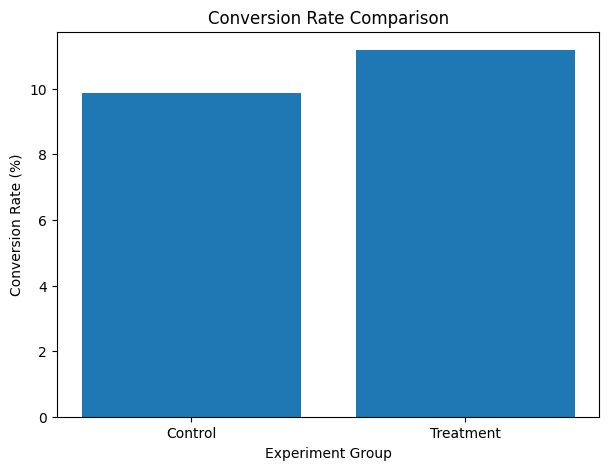

/tmp/ipykernel_452/702360045.py:208: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


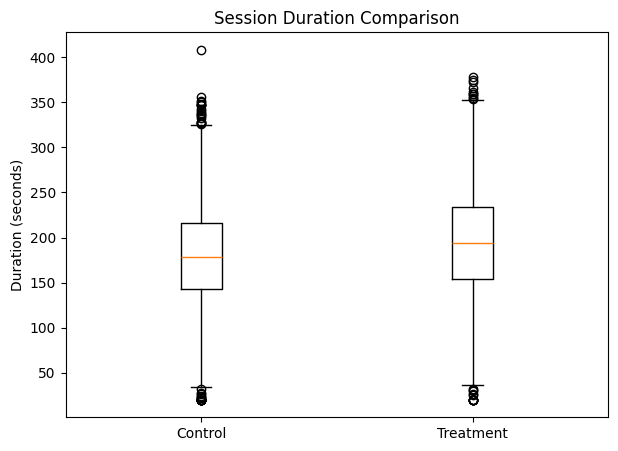


--- FINAL EXPERIMENT DECISION ---
Statistically significant difference found.
Recommendation: SHIP IT
Reason: The improvement is statistically significant and meets the practical lift threshold.

--- FINAL SUMMARY REPORT ---
                                       Metric        Value
                  Control Conversion Rate (%) 9.860000e+00
                Treatment Conversion Rate (%) 1.118000e+01
            Absolute Lift (percentage points) 1.320000e+00
                            Relative Lift (%) 1.338742e+01
                                  Z Statistic 2.151162e+00
                                      P-value 3.146343e-02
Confidence Interval Lower (percentage points) 1.175794e-01
Confidence Interval Upper (percentage points) 2.522421e+00
                                    Cohen's H 4.304307e-02
                     Session Duration P-value 3.363102e-38

Reports Exported Successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# TASK 3: A/B TEST ANALYSIS FOR PRODUCT FEATURE ROLLOUT

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from google.colab import files

# 1. UPLOAD DATASET
uploaded = files.upload()
file_name = next(iter(uploaded))
data = pd.read_csv(file_name)

print("Dataset Loaded Successfully!")
print(data.head())

# 2. DATA UNDERSTANDING
print("\nDataset Shape:", data.shape)
print("\nColumn Information:")
print(data.info())

print("\nMissing Values:")
print(data.isnull().sum())

print("\nDuplicate Rows:", data.duplicated().sum())

# 3. DATA CLEANING
data = data.drop_duplicates()
data = data.dropna(subset=[
    "user_id", "group", "converted",
    "session_duration_seconds", "revenue"
])

data["group"] = data["group"].str.lower().str.strip()
data["converted"] = pd.to_numeric(data["converted"], errors="coerce")
data["session_duration_seconds"] = pd.to_numeric(
    data["session_duration_seconds"], errors="coerce"
)
data["revenue"] = pd.to_numeric(data["revenue"], errors="coerce")

data = data.dropna()

data = data[
    data["group"].isin(["control", "treatment"]) &
    data["converted"].isin([0, 1]) &
    (data["session_duration_seconds"] >= 0) &
    (data["revenue"] >= 0)
].copy()

print("\nCleaned Dataset Shape:", data.shape)

# 4. SEPARATE CONTROL AND TREATMENT GROUPS
control = data[data["group"] == "control"]
treatment = data[data["group"] == "treatment"]

n_control = len(control)
n_treatment = len(treatment)

print("\nControl Users:", n_control)
print("Treatment Users:", n_treatment)

# 5. CALCULATE CONVERSION RATES
control_conversions = control["converted"].sum()
treatment_conversions = treatment["converted"].sum()

control_rate = control["converted"].mean()
treatment_rate = treatment["converted"].mean()

absolute_lift = treatment_rate - control_rate

relative_lift = (
    (absolute_lift / control_rate) * 100
    if control_rate > 0 else np.nan
)

print("\n--- CONVERSION ANALYSIS ---")
print("Control Conversions:", int(control_conversions))
print("Treatment Conversions:", int(treatment_conversions))
print("Control Conversion Rate:", round(control_rate * 100, 2), "%")
print("Treatment Conversion Rate:", round(treatment_rate * 100, 2), "%")
print("Absolute Lift:", round(absolute_lift * 100, 2), "percentage points")
print("Relative Lift:", round(relative_lift, 2), "%")

# 6. STATE HYPOTHESES
print("\n--- HYPOTHESIS TESTING ---")
print("H0: There is no difference in conversion rates.")
print("H1: There is a difference in conversion rates.")

# 7. TWO-PROPORTION Z-TEST
# Appropriate for comparing two independent conversion proportions.

successes = np.array([
    treatment_conversions,
    control_conversions
])

samples = np.array([
    n_treatment,
    n_control
])

pooled_rate = successes.sum() / samples.sum()

standard_error_null = np.sqrt(
    pooled_rate * (1 - pooled_rate) *
    (1 / n_treatment + 1 / n_control)
)

if standard_error_null > 0:
    z_statistic = absolute_lift / standard_error_null
    p_value = 2 * stats.norm.sf(abs(z_statistic))
else:
    z_statistic = 0
    p_value = 1.0

print("\nZ Statistic:", round(z_statistic, 4))
print("P-value:", round(p_value, 6))

# 8. 95% CONFIDENCE INTERVAL FOR CONVERSION RATE DIFFERENCE
standard_error_ci = np.sqrt(
    (treatment_rate * (1 - treatment_rate) / n_treatment) +
    (control_rate * (1 - control_rate) / n_control)
)

ci_lower = absolute_lift - 1.96 * standard_error_ci
ci_upper = absolute_lift + 1.96 * standard_error_ci

print("\n95% Confidence Interval:")
print(
    round(ci_lower * 100, 2), "to",
    round(ci_upper * 100, 2), "percentage points"
)

# 9. EFFECT SIZE - COHEN'S H
cohen_h = 2 * (
    np.arcsin(np.sqrt(treatment_rate)) -
    np.arcsin(np.sqrt(control_rate))
)

print("\nCohen's H Effect Size:", round(cohen_h, 4))

# 10. TEST ASSUMPTIONS
expected_control_success = n_control * pooled_rate
expected_control_failure = n_control * (1 - pooled_rate)
expected_treatment_success = n_treatment * pooled_rate
expected_treatment_failure = n_treatment * (1 - pooled_rate)

print("\n--- ASSUMPTION CHECKS ---")
print("Expected Control Success:", round(expected_control_success, 2))
print("Expected Control Failure:", round(expected_control_failure, 2))
print("Expected Treatment Success:", round(expected_treatment_success, 2))
print("Expected Treatment Failure:", round(expected_treatment_failure, 2))

if min(
    expected_control_success,
    expected_control_failure,
    expected_treatment_success,
    expected_treatment_failure
) >= 5:
    print("Sample size condition: Satisfied")
else:
    print("Sample size condition: Not satisfied")

print("Independence: Assumed (each user should appear only once).")
print("Random assignment: Must be confirmed from experiment design.")

# 11. CONTINUOUS METRIC ANALYSIS - SESSION DURATION
# Welch's t-test compares average session duration between groups.

t_stat, duration_p = stats.ttest_ind(
    treatment["session_duration_seconds"],
    control["session_duration_seconds"],
    equal_var=False
)

print("\n--- SESSION DURATION ANALYSIS ---")
print(
    "Control Average:",
    round(control["session_duration_seconds"].mean(), 2),
    "seconds"
)
print(
    "Treatment Average:",
    round(treatment["session_duration_seconds"].mean(), 2),
    "seconds"
)
print("Welch T-test Statistic:", round(t_stat, 4))
print("Session Duration P-value:", round(duration_p, 6))

# 12. VISUALIZATION
conversion_rates = [
    control_rate * 100,
    treatment_rate * 100
]

plt.figure(figsize=(7, 5))
plt.bar(
    ["Control", "Treatment"],
    conversion_rates
)
plt.title("Conversion Rate Comparison")
plt.ylabel("Conversion Rate (%)")
plt.xlabel("Experiment Group")
plt.show()

# Session duration comparison
plt.figure(figsize=(7, 5))
plt.boxplot(
    [
        control["session_duration_seconds"],
        treatment["session_duration_seconds"]
    ],
    labels=["Control", "Treatment"]
)
plt.title("Session Duration Comparison")
plt.ylabel("Duration (seconds)")
plt.show()

# 13. STATISTICAL DECISION
alpha = 0.05

print("\n--- FINAL EXPERIMENT DECISION ---")

if p_value < alpha:
    print("Statistically significant difference found.")
else:
    print("No statistically significant difference found.")

# 14. PRACTICAL SIGNIFICANCE AND ROLLOUT RECOMMENDATION
# Minimum useful improvement is set to 1 percentage point
minimum_practical_lift = 0.01

if p_value >= alpha:
    recommendation = "NEED MORE DATA"
    reason = "The observed difference is not statistically significant."

elif absolute_lift >= minimum_practical_lift:
    recommendation = "SHIP IT"
    reason = "The improvement is statistically significant and meets the practical lift threshold."

else:
    recommendation = "DON'T SHIP IT"
    reason = "The difference is statistically significant but below the practical lift threshold."

print("Recommendation:", recommendation)
print("Reason:", reason)

# 15. SUMMARY REPORT
summary = pd.DataFrame({
    "Metric": [
        "Control Conversion Rate (%)",
        "Treatment Conversion Rate (%)",
        "Absolute Lift (percentage points)",
        "Relative Lift (%)",
        "Z Statistic",
        "P-value",
        "Confidence Interval Lower (percentage points)",
        "Confidence Interval Upper (percentage points)",
        "Cohen's H",
        "Session Duration P-value"
    ],
    "Value": [
        control_rate * 100,
        treatment_rate * 100,
        absolute_lift * 100,
        relative_lift,
        z_statistic,
        p_value,
        ci_lower * 100,
        ci_upper * 100,
        cohen_h,
        duration_p
    ]
})

print("\n--- FINAL SUMMARY REPORT ---")
print(summary.to_string(index=False))

summary.to_csv("Task_3_AB_Test_Summary.csv", index=False)
data.to_csv("Task_3_AB_Test_Cleaned.csv", index=False)

print("\nReports Exported Successfully!")

files.download("Task_3_AB_Test_Summary.csv")
files.download("Task_3_AB_Test_Cleaned.csv")
